# Compare wasabi_online sessions

Compares stim-selection strategies run on the same simulated ground truth and control trials
(same `session.seed` and `num_control`): uncertainty in B, reconstruction loss, time per step, and which
stim groups each strategy chose.

Edit `RUNS` to compare other sessions. Each strategy keeps its own colour in every plot.

In [62]:
RUNS = {  # label: history file, relative to the WASABI repo
    "D-optimal": "results/simulation/history_doptimal_20261104_091108.npz",  # same seed, also saves the scores
    "Tile": "results/simulation/history_tiled_20261104_084330.npz",
    "Random": "results/simulation/history_random_20261104_084330.npz",
}
GROUP_SIZE = 4   # channels per stim group, as stim.group_size in the config

In [63]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()

# Categorical slots 1-3 of the validated default palette, fixed per strategy
COLORS = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a"]))
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e4e3df"
plt.rcParams.update({
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 11, "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 1.6,
})


def load_history(path: Path) -> dict:
    """The history as a dict, with NaN for entries older sessions did not record."""
    h = dict(np.load(path))
    n = len(h["choice"])
    for key, length in (("load_s", n), ("fitting_s", n), ("acquisition_s", n + 1), ("decided_at", n + 1)):
        h.setdefault(key, np.full(length, np.nan))
    h.setdefault("control_fit_s", np.nan)
    h.setdefault("control_fit_losses", np.array([np.nan]))
    h.setdefault("control_fit_converged", False)
    # (n_trials, n_groups) True where the group was stimulated on that trial
    patterns = h["candidates"][h["choice"]]
    h["groups_on"] = patterns.reshape(n, -1, GROUP_SIZE).any(axis=2)
    return h


H = {name: load_history(ROOT / path) for name, path in RUNS.items()}

# The comparison is only fair if every run started from the same control fit. Same seed gives
# the same control trials, but GPU float rounding can differ slightly between runs.
ref_name, ref = next(iter(H)), next(iter(H.values()))["control_fit_losses"]
for name, h in H.items():
    losses = h["control_fit_losses"]
    if losses.shape != ref.shape:
        print(f"{name}: control fit took {len(losses)} steps vs {len(ref)} for {ref_name} -- different control data or settings?")
        continue
    rel = np.max(np.abs(losses - ref) / np.abs(ref))
    verdict = "same" if rel < 1e-4 else "DIFFERENT -- check seed / num_control"
    print(f"{name:10s} control fit vs {ref_name}: max relative difference {rel:.1e} ({verdict})")

D-optimal  control fit vs D-optimal: max relative difference 0.0e+00 (same)
Tile: control fit took 800 steps vs 750 for D-optimal -- different control data or settings?
Random     control fit vs D-optimal: max relative difference 0.0e+00 (same)


## Summary

`fitting` and `acquisition` medians leave out the first trial / first stim, which include JIT compilation.
`biggest NLL jump` flags a refit that diverged.

In [64]:
checkpoints = [49, 99, 249, 499]
header = (f"{'':10s} {'trials':>6s}  " + "  ".join(f"logdet@{t + 1:<3d}" for t in checkpoints)
          + f"  {'NLL start':>9s} {'end':>7s}  {'biggest NLL jump':>17s}  {'distinct':>8s} {'singles':>7s}"
          + f"  {'per group':>9s}  {'fitting':>7s} {'acq.':>6s}")
print(header)
for name, h in H.items():
    ld, nll, n = h["logdet"], h["refit_loss"], len(h["choice"])
    jumps = np.diff(nll); j = int(np.argmax(jumps))
    per_group = h["groups_on"].sum(0)
    print(
        f"{name:10s} {n:6d}  " + "  ".join(f"{ld[t]:10.1f}" if t < n else f"{'-':>10s}" for t in checkpoints)
        + f"  {nll[0]:9.2f} {nll[-1]:7.2f}  {jumps[j]:+8.2f} at {j + 1:<4d}  {len(set(h['choice'])):8d}"
        + f" {int((h['groups_on'].sum(1) == 1).sum()):7d}  {int(per_group.min()):3d}-{int(per_group.max()):<5d}"
        + f"  {np.median(h['fitting_s'][1:]):6.2f}s {np.median(h['acquisition_s'][2:]):5.3f}s"
    )

           trials  logdet@50   logdet@100  logdet@250  logdet@500  NLL start     end   biggest NLL jump  distinct singles  per group  fitting   acq.
D-optimal     500      -134.5      -171.8      -210.8      -285.7     150.14  149.92     +0.10 at 3          100       0    3-96       0.42s 0.040s
Tile          500      -105.7      -150.2      -202.5      -265.0     150.09  149.88     +0.10 at 7          210      60   44-60       0.42s 0.000s
Random        500      -123.8      -155.7      -219.6      -286.5     150.09  149.88     +0.08 at 2          193      45   39-56       0.42s 0.001s


## Uncertainty in B, reconstruction loss and error against the ground truth

Lower log det = more certain about B. It measures certainty, not correctness, so simulated
sessions also record `effect_err`: the relative error of the stim effect B u over the candidate
set, against the ground-truth B in the fitted latent basis (as in `joint_ekf_simulation.py`).
The third panel appears when the histories have it (sessions run with `--source sim`).

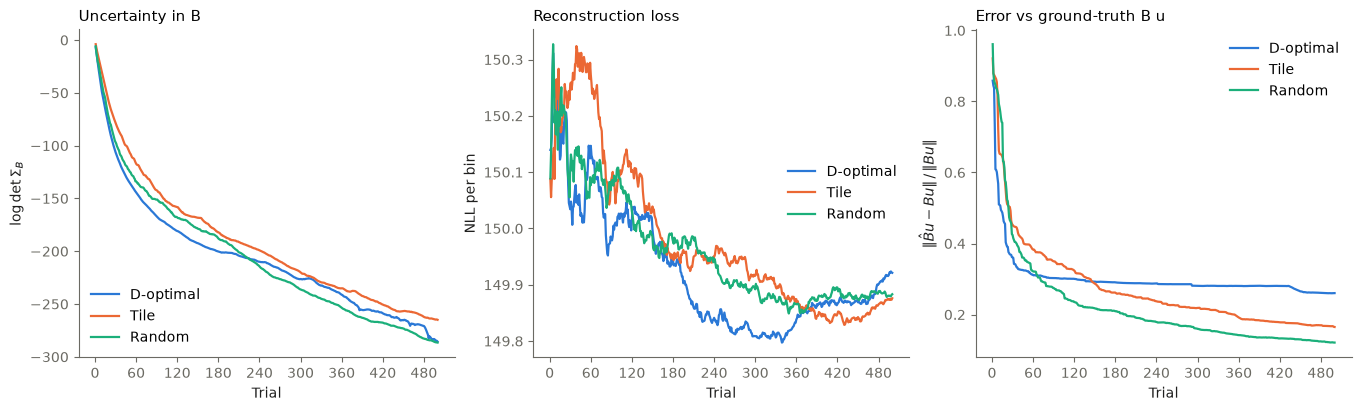

In [ ]:
has_err = [name for name, h in H.items() if "effect_err" in h]
fig, axes = plt.subplots(1, 3 if has_err else 2, figsize=(13.5 if has_err else 13, 4), constrained_layout=True)
for name, h in H.items():
    trials = np.arange(1, len(h["choice"]) + 1)
    axes[0].plot(trials, h["logdet"], color=COLORS[name], label=name)
    axes[1].plot(trials, h["refit_loss"], color=COLORS[name], label=name)
    if name in has_err:
        axes[2].plot(trials, h["effect_err"], color=COLORS[name], label=name)
axes[0].set(xlabel="Trial", ylabel=r"$\log\det \Sigma_B$", title="Uncertainty in B")
axes[1].set(xlabel="Trial", ylabel="NLL per bin", title="Reconstruction loss")
# Legends in the corners the lines leave empty
axes[0].legend(loc="lower left")
axes[1].legend(loc="center right")
if has_err:
    axes[2].set(xlabel="Trial", ylabel=r"$\|\hat{B}u - Bu\| \,/\, \|Bu\|$", title="Error vs ground-truth B u")
    axes[2].legend(loc="upper right")
    missing = [name for name in H if name not in has_err]
    if missing:
        print(f"no effect_err in {', '.join(missing)} (not a sim session, or recorded before it was added)")
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

Reconstruction loss on a narrow range, to see the trend before any divergence (lines that jump
leave the top of the plot).

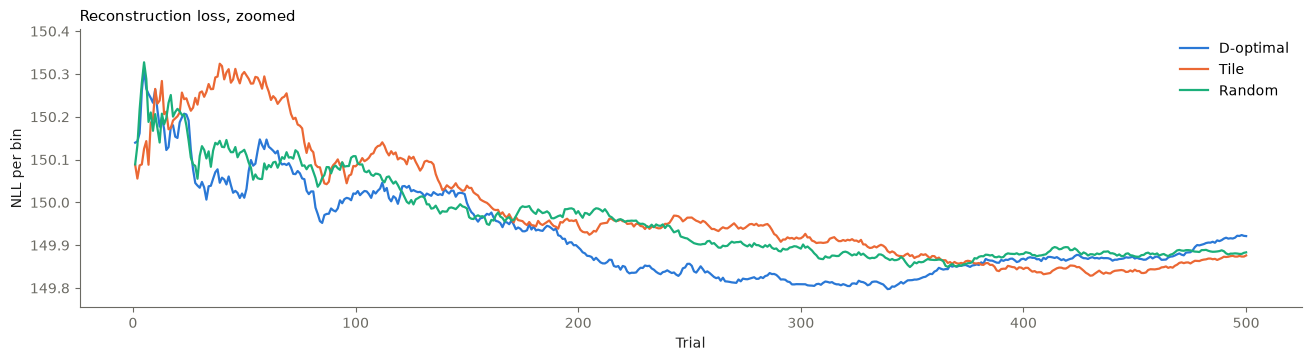

In [66]:
fig, ax = plt.subplots(figsize=(13, 3.5), constrained_layout=True)
for name, h in H.items():
    ax.plot(np.arange(1, len(h["choice"]) + 1), h["refit_loss"], color=COLORS[name], label=name)
lo = min(np.percentile(h["refit_loss"], 1) for h in H.values())
ax.set(ylim=(lo - 0.05, lo + 0.6), xlabel="Trial", ylabel="NLL per bin", title="Reconstruction loss, zoomed")
ax.legend(loc="upper right")
plt.show()

## Time per step

Fitting (filter + refit) and acquisition (choosing the next stim) on separate axes, as they
differ by an order of magnitude. Trial 1 / the first stim include JIT compilation and are left out.
Sessions run at the same time share the GPU, which slows them down, so compare timings only
between sessions run alone.

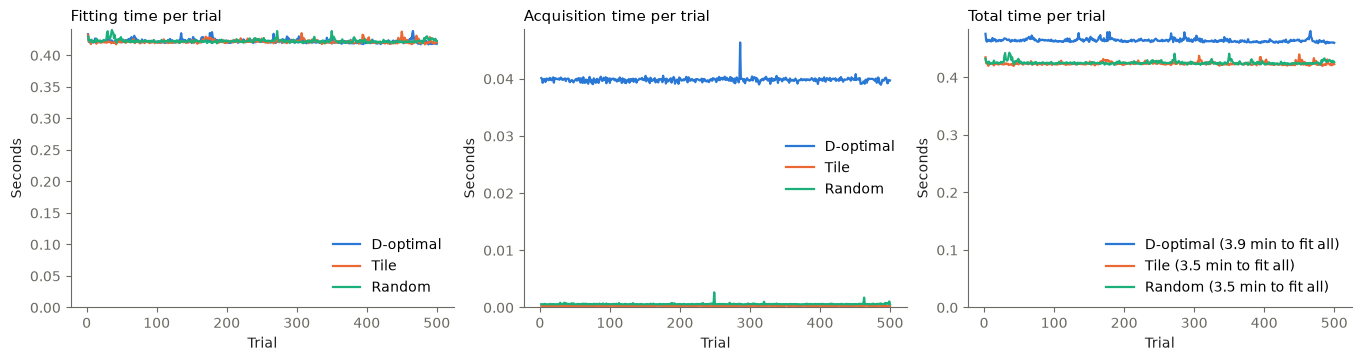

In [75]:
def total_time(h):
    """Load + fitting + the acquisition for the next stim, per trial: roughly the time between
    trials. Missing stages (e.g. load_s in older histories) count as 0."""
    n = len(h["choice"])
    acquisition = np.full(n, np.nan)
    after = h["acquisition_s"][1:n + 1]  # acquisition_s[t] is the decision after trial t
    acquisition[:len(after)] = after
    return np.nansum(np.stack([h["load_s"][:n], h["fitting_s"][:n], acquisition]), axis=0)


fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.5), constrained_layout=True)
for name, h in H.items():
    trials = np.arange(1, len(h["choice"]) + 1)
    axes[0].plot(trials[1:], h["fitting_s"][1:], color=COLORS[name], label=name)
    axes[1].plot(trials[1:], h["acquisition_s"][2:], color=COLORS[name], label=name)
    total = total_time(h)
    # Trial 1 includes JIT compilation, so the session total leaves it out like the plot
    axes[2].plot(trials[1:], total[1:], color=COLORS[name], label=f"{name} ({total[1:].sum() / 60:.1f} min to fit all)")
axes[0].set(xlabel="Trial", ylabel="Seconds", title="Fitting time per trial")
axes[1].set(xlabel="Trial", ylabel="Seconds", title="Acquisition time per trial")
axes[2].set(xlabel="Trial", ylabel="Seconds", title="Total time per trial")
for ax in axes:
    ax.set_ylim(bottom=0)
# Legends where the lines leave room: fitting and total sit near the top, acquisition splits
axes[0].legend(loc="lower right")
axes[1].legend(loc="center right")
axes[2].legend(loc="lower right")
plt.show()

### D-optimal: where the time goes on each trial

Loading the trial, fitting (joint filter + refit) and acquisition (scoring the candidates for
the next stim) for one run, on one log axis since they differ by orders of magnitude. The time
between trials is roughly their sum. Trial 1's fitting and the first two stim decisions include
JIT compilation and are left out, as above.

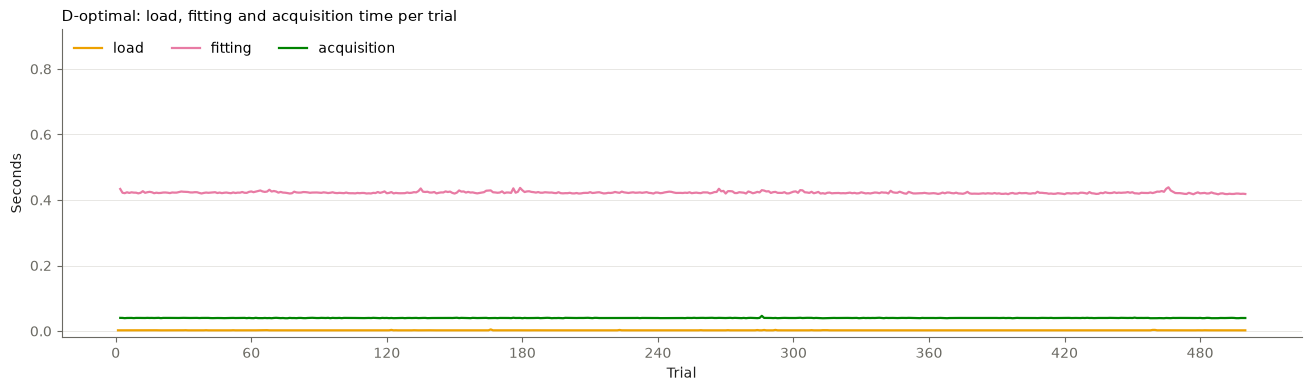

In [79]:
TIMING_RUN = "D-optimal"
# Categorical slots 4-6, so the stages are not mistaken for the strategy colours above
STAGE_COLORS = {"load": "#eda100", "fitting": "#e87ba4", "acquisition": "#008300"}

h = H[TIMING_RUN]
n = len(h["choice"])
trials = np.arange(1, n + 1)
# acquisition_s[t] is the decision made after trial t (entry 0 is the first stim)
acquisition = h["acquisition_s"][1:]
stages = {
    "load": (trials, h["load_s"]),
    "fitting": (trials[1:], h["fitting_s"][1:]),
    "acquisition": (trials[1:len(acquisition)], acquisition[1:]),
}

fig, ax = plt.subplots(figsize=(13, 3.8), constrained_layout=True)
for stage, (x, y) in stages.items():
    y = np.where(y > 0, y, np.nan)  # log axis
    if np.isfinite(y).any():
        ax.plot(x, y, color=STAGE_COLORS[stage], label=f"{stage}")
    else:
        print(f"{TIMING_RUN}: no {stage} times recorded")
# ax.set_yscale("log")
ax.grid(axis="y", which="major")
ax.set(xlabel="Trial", ylabel="Seconds", title=f"{TIMING_RUN}: load, fitting and acquisition time per trial")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylim(top=ax.get_ylim()[1] * 2)  # headroom so the legend clears the lines
ax.legend(loc="upper left", ncols=3)
plt.show()

## Which groups were stimulated

How often each stim group was switched on, and the group pattern on every trial.

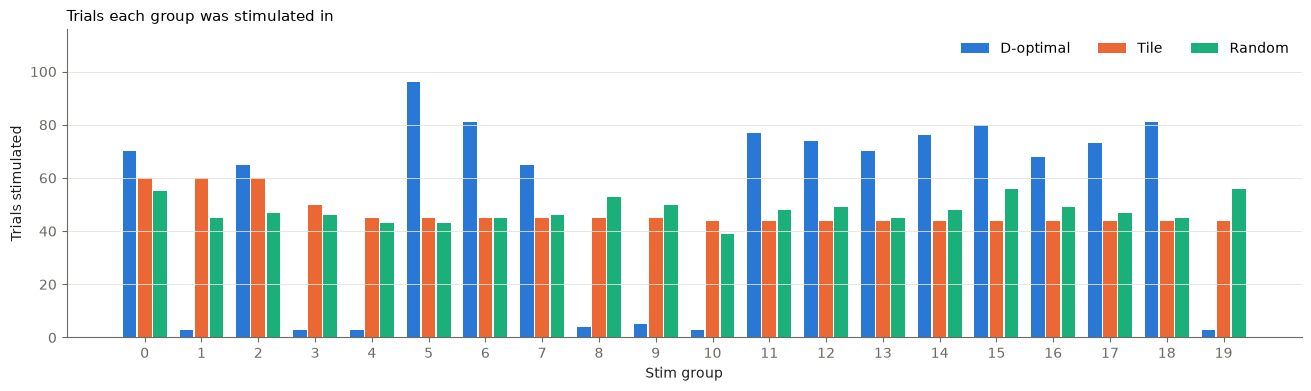

In [69]:
names = list(H)
num_groups = next(iter(H.values()))["groups_on"].shape[1]
width = 0.8 / len(names)
fig, ax = plt.subplots(figsize=(13, 3.8), constrained_layout=True)
for i, name in enumerate(names):
    x = np.arange(num_groups) + (i - (len(names) - 1) / 2) * width
    # Bars a hair narrower than their slot leave a surface gap between neighbours
    ax.bar(x, H[name]["groups_on"].sum(0), width=width * 0.9, color=COLORS[name], label=name)
ax.set(xlabel="Stim group", ylabel="Trials stimulated", title="Trials each group was stimulated in",
       xticks=np.arange(num_groups))
ax.grid(axis="y")  # horizontal lines on bar charts only
ax.set_ylim(top=ax.get_ylim()[1] * 1.15)  # headroom so the legend clears the bars
ax.legend(loc="upper right", ncols=len(names))
plt.show()

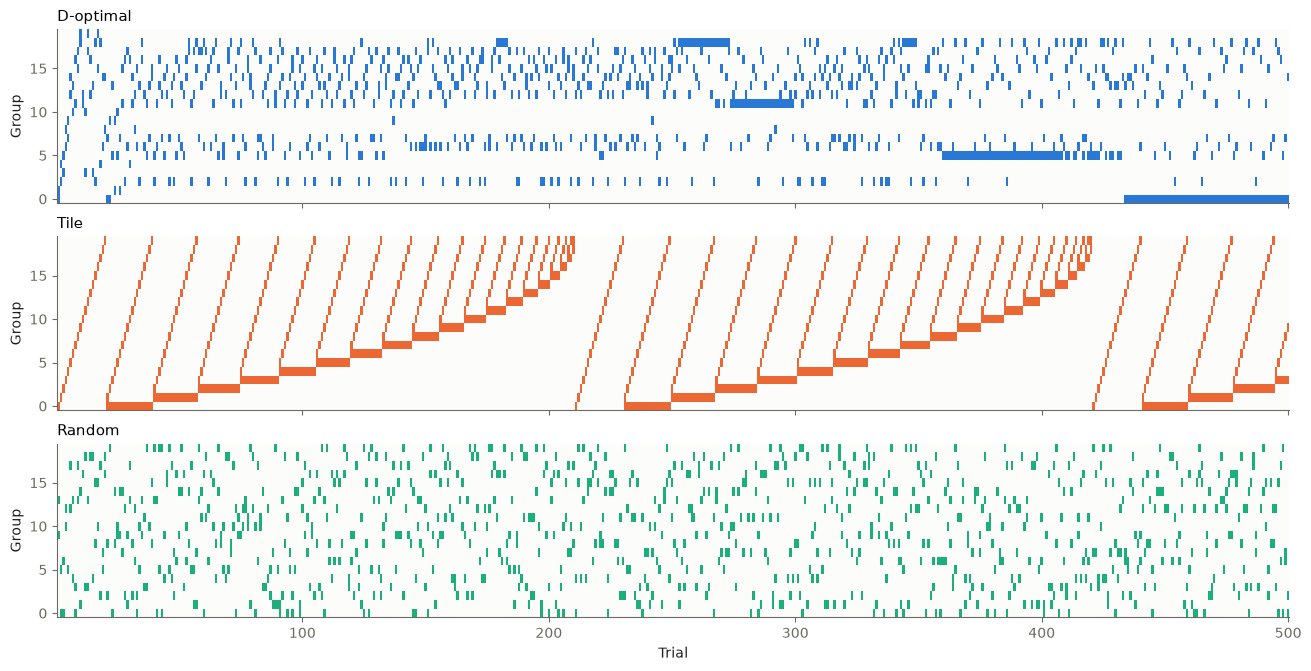

In [73]:
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(len(names), 1, figsize=(13, 2.2 * len(names)), sharex=True, constrained_layout=True)
for ax, name in zip(np.atleast_1d(axes), names):
    on = H[name]["groups_on"].T  # (groups, trials)
    ax.imshow(on, aspect="auto", interpolation="nearest", origin="lower",
              cmap=ListedColormap(["#fcfcfb", COLORS[name]]), extent=(0.5, on.shape[1] + 0.5, -0.5, num_groups - 0.5))
    ax.set(ylabel="Group", title=f"{name}")
np.atleast_1d(axes)[-1].set_xlabel("Trial")
plt.show()

## D-optimal decision variable

What D-optimal minimizes before each trial: every candidate's expected log det of the B
covariance at the end of the upcoming trial, from rolling the joint EKF through it with zero
innovation (`selection.expected_final_logdets`). Shown as the expected drop from the prior's
log det, prior − score, so higher = more informative and the chosen stim is the highest.
The snapshot at trial $t$ is the decision for trial $t$, made after $t - 1$ trials. Each panel
has its own scale: the gains shrink as B is pinned down. Needs a history that saved the
scores (`scores`, D-optimal runs since they were added).

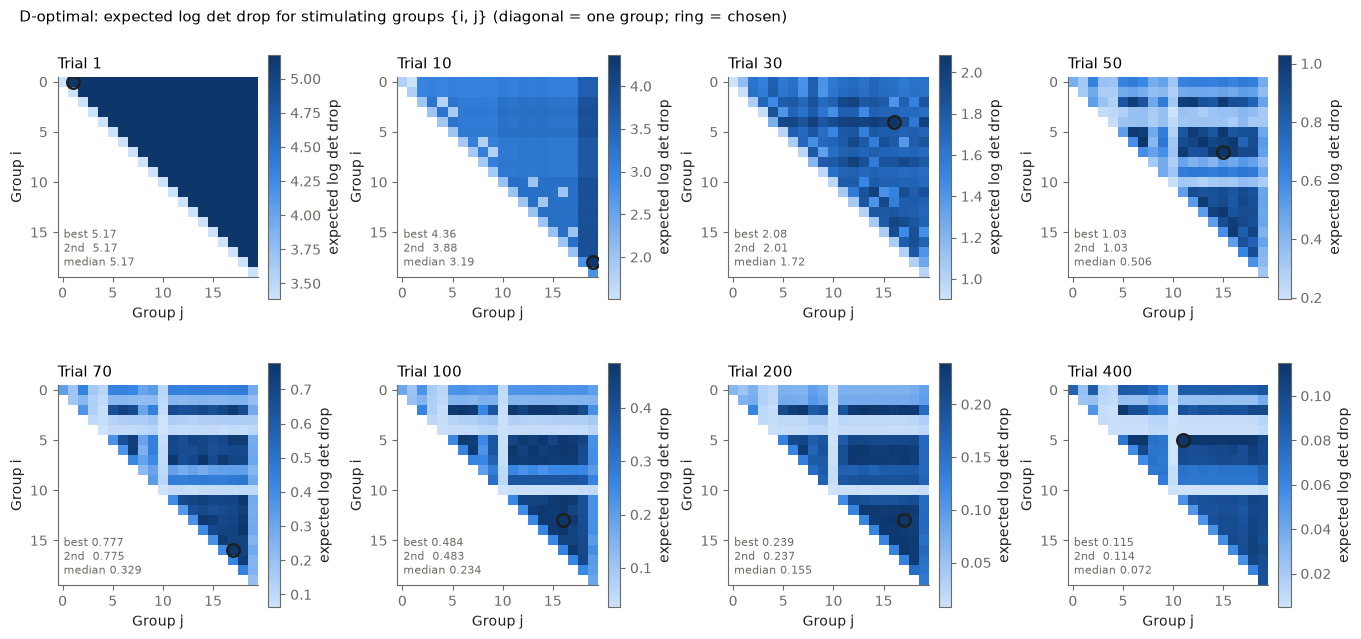

In [71]:
SCORE_RUN = "D-optimal"
SNAPSHOTS = [1, 10, 30, 50, 70, 100, 200, 400]  # trials whose decision to show

h = H[SCORE_RUN]
if "scores" not in h:
    raise KeyError(f"{SCORE_RUN}: history has no scores; rerun it with the current wasabi_online.py")
gain = h["score_prior_logdet"][:, None] - h["scores"]  # (decisions, candidates)
cand_groups = [tuple(np.flatnonzero(p.reshape(-1, GROUP_SIZE).any(1))) for p in h["candidates"]]
num_groups = h["candidates"].shape[1] // GROUP_SIZE
pair = -np.ones((num_groups, num_groups), dtype=int)  # candidate of groups {i, j}; i == j: single
for c, g in enumerate(cand_groups):
    i, j = g[0], g[-1]
    pair[min(i, j), max(i, j)] = c
snaps = [t for t in SNAPSHOTS if t <= len(gain)]

seq = matplotlib.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
cols = 4
fig, axes = plt.subplots(-(-len(snaps) // cols), cols, figsize=(13.5, 3.2 * -(-len(snaps) // cols)),
                         constrained_layout=True, squeeze=False)
for ax, t in zip(axes.flat, snaps):
    g = gain[t - 1]
    M = np.where(pair >= 0, g[np.maximum(pair, 0)], np.nan)  # upper triangle, each pair once
    im = ax.imshow(M, cmap=seq, origin="upper", interpolation="nearest")
    chosen = cand_groups[h["choice"][t - 1]]
    ax.plot(chosen[-1], chosen[0], marker="o", markersize=9, markerfacecolor="none",
            markeredgecolor=INK, markeredgewidth=1.8)
    top2 = np.sort(g[np.isfinite(g)])[-2:]
    ax.set(title=f"Trial {t}", xlabel="Group j", ylabel="Group i",
           xticks=range(0, num_groups, 5), yticks=range(0, num_groups, 5))
    ax.text(0.03, 0.04, f"best {top2[1]:.3g}\n2nd  {top2[0]:.3g}\nmedian {np.nanmedian(g):.3g}",
            transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom")
    fig.colorbar(im, ax=ax, shrink=0.85, label="expected log det drop")
for ax in axes.flat[len(snaps):]:
    ax.set_visible(False)
fig.suptitle(f"{SCORE_RUN}: expected log det drop for stimulating groups {{i, j}} "
             "(diagonal = one group; ring = chosen)", x=0.01, ha="left", fontsize=11)
plt.show()

Per group, the expected drop from stimulating that group alone (the diagonal above), over the
whole session, on a linear and a log scale. Groups that stay at the bottom are the ones D-optimal stops choosing.

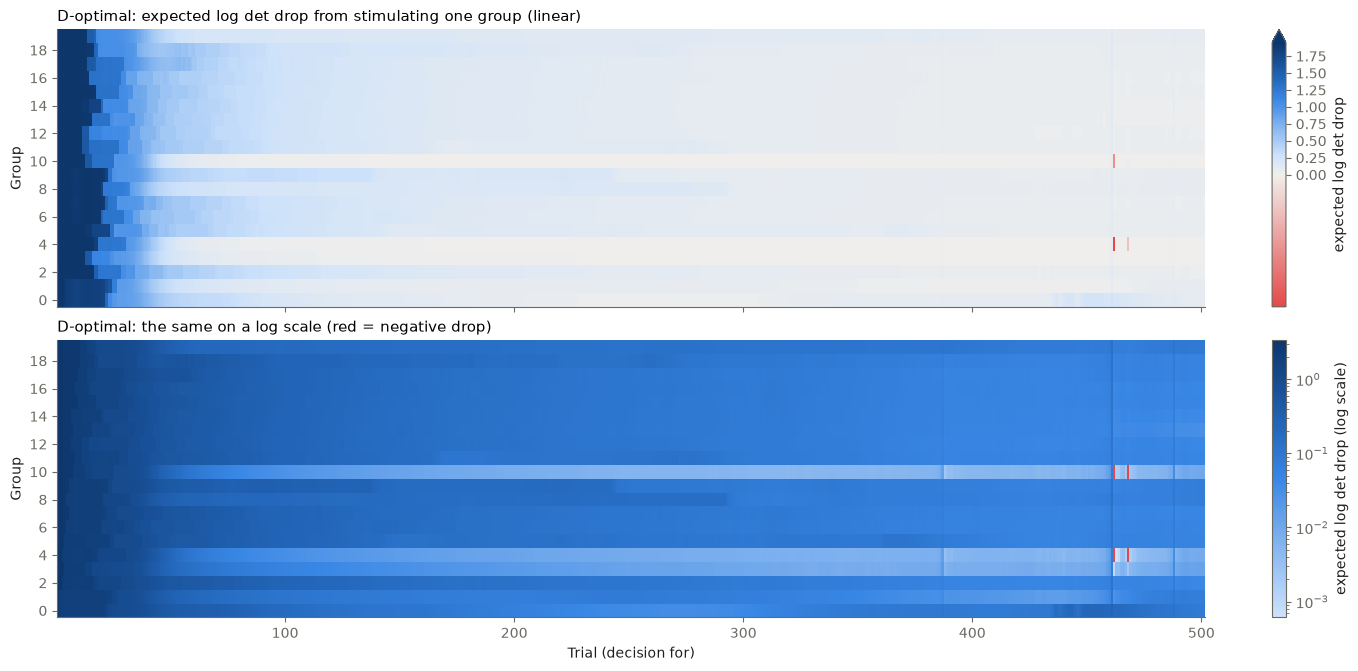

2 decisions have a candidate with a negative expected drop: the B covariance update went the wrong way, a sign of numerical error


In [80]:
singles = np.array([pair[g, g] for g in range(num_groups)])
G = gain[:, singles]  # (decisions, groups)
fig, axes = plt.subplots(2, 1, figsize=(13.5, 6.6), sharex=True, constrained_layout=True)
extent = (0.5, len(G) + 0.5, -0.5, num_groups - 0.5)
pos = ["#f0efec", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

# Linear scale. Positive drops in blue, negative ones (numerical error) in red, neutral at 0;
# the top of the scale is the 98th percentile so the first few trials, whose drops are much
# larger than the rest, do not wash out the session (colorbar arrow = clipped).
# TwoSlopeNorm puts 0 at the middle of the colormap, so the neutral sits at 0.5
nodes = [(0.0, "#e34948"), (0.5, pos[0])] + [(0.5 + 0.5 * k / (len(pos) - 1), col) for k, col in enumerate(pos[1:], 1)]
div = matplotlib.colors.LinearSegmentedColormap.from_list("div", nodes)
vmax = np.nanpercentile(G, 98)
vmin = min(np.nanmin(G), -1e-6 * vmax)
im = axes[0].imshow(G.T, aspect="auto", interpolation="nearest", origin="lower", cmap=div,
                    norm=matplotlib.colors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax), extent=extent)
fig.colorbar(im, ax=axes[0], label="expected log det drop", extend="max")
axes[0].set_title(f"{SCORE_RUN}: expected log det drop from stimulating one group (linear)")

# Log scale: positive drops only; negative ones cannot be shown on it, so they are solid red
seq = matplotlib.colors.LinearSegmentedColormap.from_list("seq_blue", pos[1:])
im = axes[1].imshow(np.ma.masked_invalid(np.where(G > 0, G, np.nan).T), aspect="auto", interpolation="nearest",
                    origin="lower", cmap=seq, norm=matplotlib.colors.LogNorm(), extent=extent)
negative = np.ma.masked_where(~(G < 0).T, np.ones_like(G.T))
axes[1].imshow(negative, aspect="auto", interpolation="nearest", origin="lower", extent=extent,
               cmap=matplotlib.colors.ListedColormap(["#e34948"]))
fig.colorbar(im, ax=axes[1], label="expected log det drop (log scale)")
axes[1].set_title(f"{SCORE_RUN}: the same on a log scale (red = negative drop)")

for ax in axes:
    ax.set(ylabel="Group", yticks=range(0, num_groups, 2))
axes[1].set_xlabel("Trial (decision for)")
plt.show()
num_neg = int((gain < 0).any(axis=1).sum())
if num_neg:
    print(f"{num_neg} decisions have a candidate with a negative expected drop: the B covariance "
          "update went the wrong way, a sign of numerical error")